# Adaptive **pure Gaussian** Pd/Qd sampling with Julia AC-OPF verification

**Notebook 1 of 2.** This version replaces only the sampling formulation of the additive-noise notebook: instead of `loads + epsilon`, it samples each absolute `[Pd,Qd]` pair directly from the empirical Gaussian fitted to the original grid's active loads. The accepted-only adaptation, Julia checks, iteration counts, plotting structure and exports are retained. No nonnegativity redraw is imposed, exactly as in `sampling_data_load(8).ipynb`.

**Important distinction:** a scenario consists of `n_loads` independently drawn *pairs* from a shared two-dimensional distribution; original individual load values are **not** preserved as sampling centers. Negative Pd/Qd can occur, and baseline loads remain the same for reference/SHAP. Julia non-acceptance is not a proof of physical infeasibility.

## 1. Imports, state/grid selection and Julia verifier

In [1]:
import copy
import csv
import hashlib
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from juliacall import Main as jl

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [2]:
DATASET_NAME = "alabama"
TIME_SLICE = "16h"
DATA_DIR = Path("../power_grid/US/gridsfm_data") / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"
JULIA_SCRIPT = Path("../verifier/acopf_verifier.jl")
OUTPUT_DIR = Path("../results/gaussian_load_pure") / DATASET_NAME
SCENARIO_PATH = OUTPUT_DIR / "acopf_labeled_scenarios.npz"
DATASET_LABEL = DATASET_NAME.replace("_", " ").title()

assert DATA_PATH.is_file(), f"Grid case not found: {DATA_PATH}"
assert JULIA_SCRIPT.is_file(), f"Julia verifier not found: {JULIA_SCRIPT}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("bus"), dict), "Expected case with a 'bus' dictionary"
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_LABEL, "| Case:", DATA_PATH)
print("Julia verifier:", JULIA_SCRIPT)
print("Output directory:", OUTPUT_DIR)
print("Buses:", len(data["bus"]), "| baseMVA:", data.get("baseMVA"))

Dataset: Alabama | Case: ../power_grid/US/gridsfm_data/16h/alabama_model.json
Julia verifier: ../verifier/acopf_verifier.jl
Output directory: ../results/gaussian_load_pure/alabama
Buses: 494 | baseMVA: 100.0


## 2. Preserve mapping between Python load rows and Julia load IDs

In [3]:
# Preserve load IDs so we can map samples back
load_ids = []
for load_id, load in data["load"].items():
    if load["status"] == 1:
        load_ids.append(load_id)

# Original load dataset: columns [Pd, Qd]
loads = []
for load_id in load_ids:
    loads.append([
        data["load"][load_id]["pd"],
        data["load"][load_id]["qd"]
    ])

loads = np.array(loads, dtype=float)
n_loads = len(load_ids)

assert n_loads >= 2, "This Gaussian covariance requires at least two active loads."
assert loads.shape == (n_loads, 2) and np.isfinite(loads).all()

print("Active loads:", n_loads, "| Shape:", loads.shape)
print("Original mean [Pd,Qd]:", loads.mean(axis=0), "| Base MVA:", data.get("baseMVA"))
print("Original total [Pd,Qd] (p.u.):", loads.sum(axis=0), "| Base MVA:", data.get("baseMVA"))


Active loads: 494 | Shape: (494, 2)
Original mean [Pd,Qd]: [0.19233127 0.08193278] | Base MVA: 100.0
Original total [Pd,Qd] (p.u.): [95.011645   40.47479128] | Base MVA: 100.0


## 3. Initialize the existing PowerModels AC-OPF verifier for this case


In [4]:
jl.include(str(JULIA_SCRIPT.resolve()))
summary_text = jl.ACOPFVerifier.initialize_case(str(DATA_PATH.resolve()))
print("Julia case initialized:\n", json.loads(str(summary_text)))


Julia case initialized:
 {'n_buses': 494, 'baseMVA': 100.0, 'supported_modes': ['branch', 'bus', 'gen', 'load'], 'initialized': True, 'n_loads': 494, 'n_generators': 55, 'n_branches': 864, 'per_unit': True}


## 4. Python wrapper and baseline AC-OPF check


In [5]:
def verify_scenario(patch):
    start = time.perf_counter()
    try:
        if not isinstance(patch, dict) or not patch:
            raise ValueError("patch must be a nonempty dictionary")
        raw = jl.ACOPFVerifier.verify_scenario_json(
            json.dumps(patch, allow_nan=False)
        )
        result = json.loads(str(raw))
        result["elapsed_s"] = time.perf_counter() - start
        return result
    except Exception as exc:
        return {
            "accepted": False, "status": "CALL_ERROR", "objective": None,
            "reason": str(exc)[:1000], "termination_status": "ERROR",
            "primal_status": "UNKNOWN", "elapsed_s": time.perf_counter() - start,
        }


def build_load_patch(candidate_loads):
    values = np.asarray(candidate_loads, dtype=float)
    if values.shape != loads.shape or not np.isfinite(values).all():
        raise ValueError(f"Expected finite shape {loads.shape}, got {values.shape}")
    return {"load": {
        str(load_id): {"pd": float(pair[0]), "qd": float(pair[1])}
        for load_id, pair in zip(load_ids, values)
    }}


def verify_acopf(candidate_limits):
    return verify_scenario(build_load_patch(candidate_limits))

In [6]:
print(f"Verifying the original {DATASET_LABEL} case")
baseline_result = verify_acopf(loads)
print("Baseline:\n", baseline_result)
if not baseline_result["accepted"]:
    raise RuntimeError("Baseline not confirmed: " + str(baseline_result))

Verifying the original Alabama case
Baseline:
 {'stage': 'opf', 'modes': ['load'], 'termination_status': 'LOCALLY_SOLVED', 'objective': 198538.08988997107, 'primal_status': 'FEASIBLE_POINT', 'reason': '', 'warnings': [], 'applied_components': {'load': 494}, 'solve_time': 2.80816912651062, 'accepted': True, 'status': 'OPF_SOLVED', 'elapsed_s': 9.166338166978676}


## 5. Pure Gaussian initialization from the absolute Pd/Qd data distribution

In [7]:
SEED = 42
iterations = 10
samples_per_iteration = 2   # Each scenario costs one Julia AC-OPF solve; change to 100/200 for a large experiment
alpha = 0.30
COV_REG = 1e-8             # Matches the regularization in the pure Gaussian reference notebook

rng = np.random.default_rng(SEED)

# Direct absolute-load Gaussian (NOT noise added to the original load at each bus).
mu = loads.mean(axis=0)
cov = np.cov(loads, rowvar=False, bias=True)
cov = 0.5 * (cov + cov.T) + np.eye(2) * COV_REG
initial_mu = mu.copy()
initial_cov = cov.copy()

history = []
verification_log = []
explain_candidates = []     # All proposed absolute load matrices for pretrained-model SHAP
explain_labels = []         # Julia screening/acceptance metadata; NOT used as GridSFM verdicts
explain_metadata = []
last_proposed = None
last_applied = None

print("Pure Gaussian parameters from original active loads:")
print("  Original loads mean [Pd, Qd]:", loads.mean(axis=0))
print("  Initial Gaussian mean:", mu)
print("  Initial Gaussian std:", np.sqrt(np.diag(cov)))
print("  Initial Gaussian covariance:\n", cov)
print("  No additive noise; no INITIAL_SCALE; no negative-value redraws")
print("  Number of grid scenarios:", iterations * samples_per_iteration)

Pure Gaussian parameters from original active loads:
  Original loads mean [Pd, Qd]: [0.19233127 0.08193278]
  Initial Gaussian mean: [0.19233127 0.08193278]
  Initial Gaussian std: [0.07970127 0.03395272]
  Initial Gaussian covariance:
 [[0.00635229 0.00270606]
 [0.00270606 0.00115279]]
  No additive noise; no INITIAL_SCALE; no negative-value redraws
  Number of grid scenarios: 20


## 6. Pure Gaussian sampler — draw absolute load values (no additive offset)

In [8]:
def sample_pure_gaussian(rng, mu, cov, n_scenarios, n_loads):
    """Sample absolute load pairs from N(mu,cov), as in sampling_data_load(8).ipynb.

    Output shape: (n_scenarios, n_loads, 2). Every bus receives an independent
    2D pair; Pd and Qd inside a pair retain the fitted covariance.
    There is intentionally NO negative-value rejection / redraw / clipping.
    """
    candidates = rng.multivariate_normal(
        mean=mu, cov=cov, size=(n_scenarios, n_loads), check_valid="raise"
    )
    assert candidates.shape == (n_scenarios, n_loads, 2)
    assert np.isfinite(candidates).all()
    return candidates


## 7. Adaptive loop — pure Gaussian proposals, Julia verifier, accepted-absolute-load update

In [9]:
# Same loop / Julia verifier / checkpoints as the additive-noise notebook,
# except: draw absolute Pd/Qd and update mu/cov from accepted ABSOLUTE values.
for iteration in range(iterations):
    sampled = sample_pure_gaussian(rng, mu, cov, samples_per_iteration, n_loads)
    good_samples_list = []
    negative_pd_after = int((sampled[..., 0] < 0).sum())
    negative_qd_after = int((sampled[..., 1] < 0).sum())
    print(f"\nIteration {iteration + 1}: directly sampled {sampled.shape}; "
          f"negative Pd pairs={negative_pd_after}, negative Qd pairs={negative_qd_after}",
          flush=True)

    for scenario_idx in range(samples_per_iteration):
        candidate_loads = sampled[scenario_idx]
        verification = verify_acopf(candidate_loads)
        deviation = np.abs(candidate_loads - loads)
        total_change_pct = 100.0 * (candidate_loads.sum(axis=0) / loads.sum(axis=0) - 1)
        row = {
            "iteration": iteration + 1,
            "scenario": scenario_idx + 1,
            "pd_change_pct": float(total_change_pct[0]),
            "qd_change_pct": float(total_change_pct[1]),
            "mean_abs_pd_change": float(deviation[:, 0].mean()),
            "mean_abs_qd_change": float(deviation[:, 1].mean()),
            "negative_pd": int((candidate_loads[:, 0] < 0).sum()),
            "negative_qd": int((candidate_loads[:, 1] < 0).sum()),
            **verification,
        }
        verification_log.append(row)
        explain_candidates.append(candidate_loads.astype(np.float32).copy())
        explain_labels.append(int(verification["accepted"]))
        explain_metadata.append((iteration + 1, scenario_idx + 1,
                                 verification["status"],
                                 verification.get("termination_status", "")))
        print(f"{iteration + 1}/{iterations}, scenario "
              f"{scenario_idx + 1}/{samples_per_iteration}: "
              f"{verification['status']} ({verification.get('termination_status')}, "
              f"{verification['elapsed_s']:.1f}s), "
              f"total Pd change={total_change_pct[0]:+.8f}%, "
              f"total Qd change={total_change_pct[1]:+.8f}%", flush=True)
        if verification.get("reason"):
            print("     Reason:", verification["reason"][:350], flush=True)
        if verification["accepted"]:
            good_samples_list.append(candidate_loads.copy())

    accepted_count = len(good_samples_list)
    good_sampled = (np.stack(good_samples_list)
                    if accepted_count else np.empty((0, n_loads, 2), dtype=float))

    if accepted_count:
        flattened = good_sampled.reshape(-1, 2)
        new_mu = flattened.mean(axis=0)
        new_cov = np.cov(flattened, rowvar=False, bias=True) if len(flattened) >= 2 else cov.copy()
        mu = (1.0 - alpha) * mu + alpha * new_mu
        cov = (1.0 - alpha) * cov + alpha * new_cov
        cov = 0.5 * (cov + cov.T) + np.eye(2) * COV_REG

    history.append({
        "iteration": iteration + 1,
        "mu": mu.copy(),
        "std": np.sqrt(np.diag(cov)).copy(),
        "cov": cov.copy(),
        "accepted_count": accepted_count,
        "rejected_count": samples_per_iteration - accepted_count,
        "acceptance_rate": accepted_count / samples_per_iteration,
        "updated": bool(accepted_count),
        "negative_pd_after": negative_pd_after,
        "negative_qd_after": negative_qd_after,
    })
    last_proposed = sampled.copy()
    last_applied = good_sampled.copy()
    # Retain exact NPZ schema expected by the model-only SHAP notebook.
    np.savez_compressed(
        SCENARIO_PATH,
        candidates=np.stack(explain_candidates),
        accepted=np.asarray(explain_labels, dtype=np.int64),
        load_ids=np.asarray(load_ids),
        dataset_name=np.asarray(DATASET_NAME),
        source_case_sha256=np.asarray(CASE_SHA256),
        source_case_path=np.asarray(str(DATA_PATH.resolve())),
        iteration=np.asarray([m[0] for m in explain_metadata]),
        scenario=np.asarray([m[1] for m in explain_metadata]),
        status=np.asarray([m[2] for m in explain_metadata]),
        termination_status=np.asarray([m[3] for m in explain_metadata]),
    )
    print(f"Iteration {iteration + 1}: accepted {accepted_count}/{samples_per_iteration}; "
          f"absolute Gaussian mean={np.round(mu, 6)}, "
          f"std={np.round(np.sqrt(np.diag(cov)), 6)}", flush=True)

print("\nFinal proposed:", last_proposed.shape if last_proposed is not None else None)
print("Final accepted:", last_applied.shape if last_applied is not None else None)
print("Overall accepted:", sum(h['accepted_count'] for h in history),
      '/', iterations * samples_per_iteration)



Iteration 1: directly sampled (2, 494, 2); negative Pd pairs=7, negative Qd pairs=7
1/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.7s), total Pd change=+1.04976076%, total Qd change=+1.04354436%
1/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+4.85492776%, total Qd change=+4.85030157%
Iteration 1: accepted 2/2; absolute Gaussian mean=[0.194035 0.082657], std=[0.07953  0.033878]

Iteration 2: directly sampled (2, 494, 2); negative Pd pairs=13, negative Qd pairs=13
2/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=-0.39331123%, total Qd change=-0.39179968%
2/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), total Pd change=+0.85467332%, total Qd change=+0.86042059%
Iteration 2: accepted 2/2; absolute Gaussian mean=[0.193657 0.082497], std=[0.079469 0.033851]

Iteration 3: directly sampled (2, 494, 2); negative Pd pairs=7, negative Qd pairs=7
3/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.7s), total Pd change=+0.55986862%, total Qd cha

## 8. Visualize Julia acceptance and **absolute** Gaussian mean / standard deviation

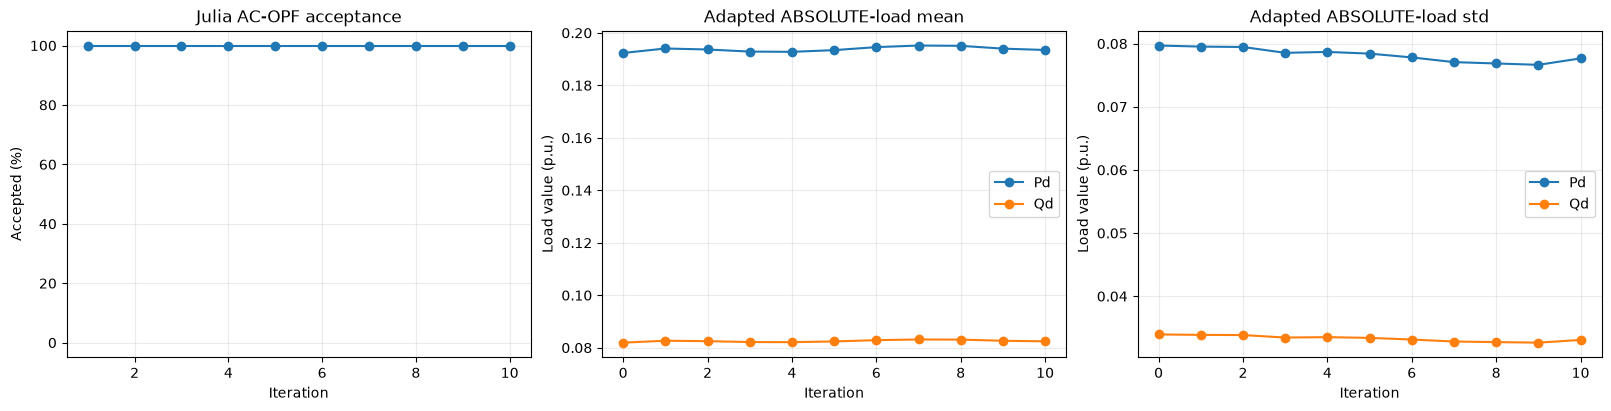

In [10]:
if not history:
    print("No iterations to plot")
else:
    xs = [h["iteration"] for h in history]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
    axes[0].plot(xs, [100*h["acceptance_rate"] for h in history], marker="o")
    axes[0].set(title="Julia AC-OPF acceptance", xlabel="Iteration", ylabel="Accepted (%)", ylim=(-5, 105))
    for j, name in enumerate(["Pd", "Qd"]):
        axes[1].plot([0]+xs, [initial_mu[j]]+[h["mu"][j] for h in history],
                     marker="o", label=name)
        axes[2].plot([0]+xs, [np.sqrt(initial_cov[j,j])]+[h["std"][j] for h in history],
                     marker="o", label=name)
    axes[1].set(title="Adapted ABSOLUTE-load mean", xlabel="Iteration", ylabel="Load value (p.u.)")
    axes[2].set(title="Adapted ABSOLUTE-load std", xlabel="Iteration", ylabel="Load value (p.u.)")
    for ax in axes:
        ax.grid(alpha=0.25)
    axes[1].legend(); axes[2].legend()
    fig.savefig(OUTPUT_DIR / "sampling_acceptance_and_gaussian.png", dpi=180, bbox_inches="tight")
    plt.show()


## 9. Plot original, proposed, and Julia-accepted absolute Pd/Qd samples

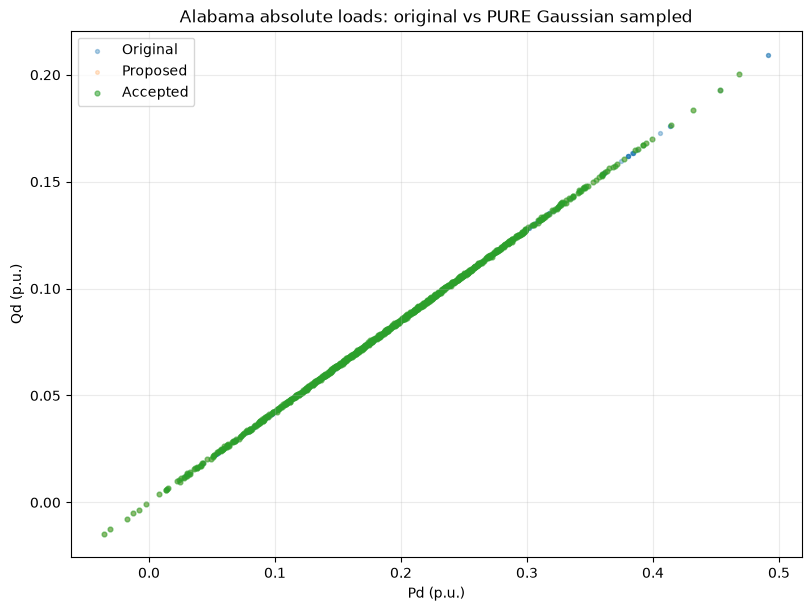

In [11]:
viz_rng = np.random.default_rng(123)
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
for arr, label, size, transparency in [
    (loads, "Original", 8, 0.35),
    (last_proposed.reshape(-1, 2), "Proposed", 7, 0.2),
    (last_applied.reshape(-1, 2), "Accepted", 12, 0.55),
]:
    if len(arr) == 0:
        continue
    idx = viz_rng.choice(len(arr), size=min(3000, len(arr)), replace=False)
    pts = arr[idx]
    ax.scatter(pts[:,0], pts[:,1], s=size, alpha=transparency, label=label, rasterized=True)
ax.set(title=f"{DATASET_LABEL} absolute loads: original vs PURE Gaussian sampled", xlabel="Pd (p.u.)", ylabel="Qd (p.u.)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 10. Export training logs (same filenames and columns wherever applicable)

In [12]:
log_path = OUTPUT_DIR / "verification_log.csv"
with log_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["iteration", "scenario", "accepted", "status", "termination_status",
            "primal_status", "objective", "solve_time", "elapsed_s", "reason",
            "pd_change_pct", "qd_change_pct", "mean_abs_pd_change",
            "mean_abs_qd_change", "negative_pd", "negative_qd"]
    writer = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(verification_log)

history_path = OUTPUT_DIR / "sampling_history.csv"
with history_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["iteration", "accepted_count", "rejected_count", "acceptance_rate",
            "updated", "negative_pd_after", "negative_qd_after",
            "gaussian_mu_pd", "gaussian_mu_qd", "gaussian_std_pd", "gaussian_std_qd"]
    writer = csv.DictWriter(f, fieldnames=cols)
    writer.writeheader()
    for h in history:
        writer.writerow({**{k: h[k] for k in cols if k in h},
                         "gaussian_mu_pd": float(h["mu"][0]),
                         "gaussian_mu_qd": float(h["mu"][1]),
                         "gaussian_std_pd": float(h["std"][0]),
                         "gaussian_std_qd": float(h["std"][1])})

print("Scenario archive:", SCENARIO_PATH)
print("Verification log:", log_path)
print("History log:", history_path)


Scenario archive: ../results/gaussian_load_pure/alabama/acopf_labeled_scenarios.npz
Verification log: ../results/gaussian_load_pure/alabama/verification_log.csv
History log: ../results/gaussian_load_pure/alabama/sampling_history.csv
